In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import scrublet as scr
import session_info

/home/Data_Drive_8TB/ahwodn/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/home/Data_Drive_8TB/ahwodn/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/home/Data_Drive_8TB/ahwodn/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/home/Data_Drive_8TB/ahwodn/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/home/Data_Drive_8TB/ahwodn/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Impor

In [2]:
import session_info
session_info.show()

In [3]:
sc.settings.verbosity = 3             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=200, facecolor='white', color_map = 'RdPu',)

In [4]:
adata_endo5=sc.read_h5ad(
    '/path/to/h5ad_subcluster/07_epi_harmony_bbk_hvg2000.h5ad')

In [5]:
res=0.62
sc.tl.leiden(adata_endo5,resolution=res,
             key_added=f'res_{res}',
             flavor='igraph',
             n_iterations=2)


running Leiden clustering
    finished: found 17 clusters and added
    'res_0.62', the cluster labels (adata.obs, categorical) (0:01:25)


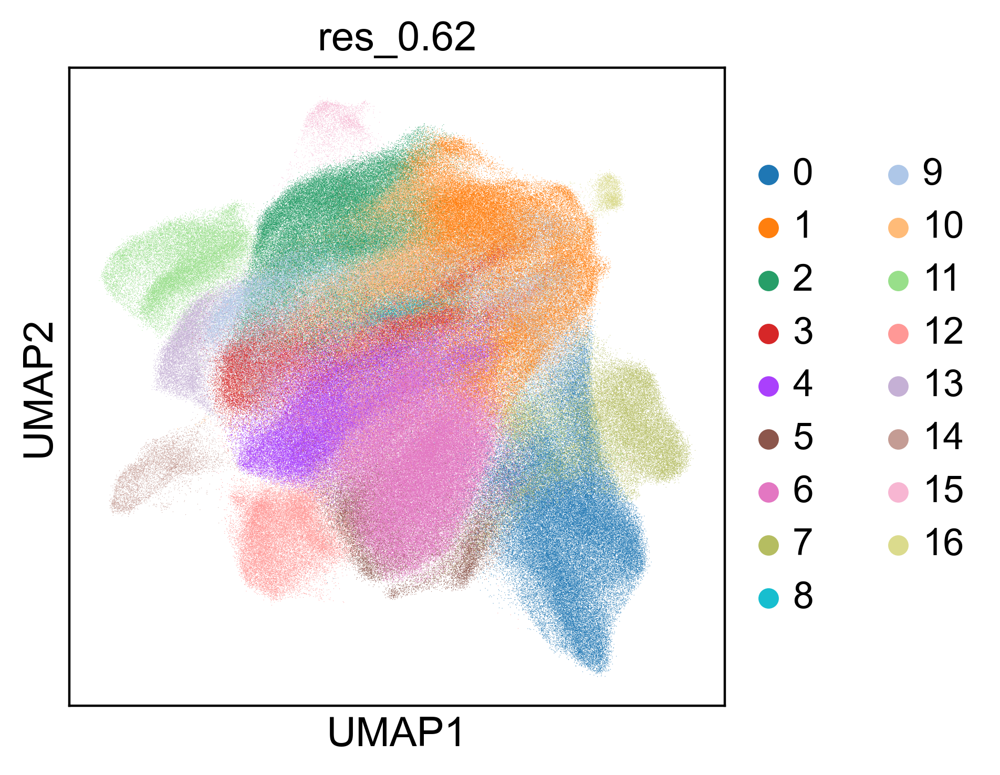

In [6]:
sc.pl.umap(adata_endo5,color='res_0.62')

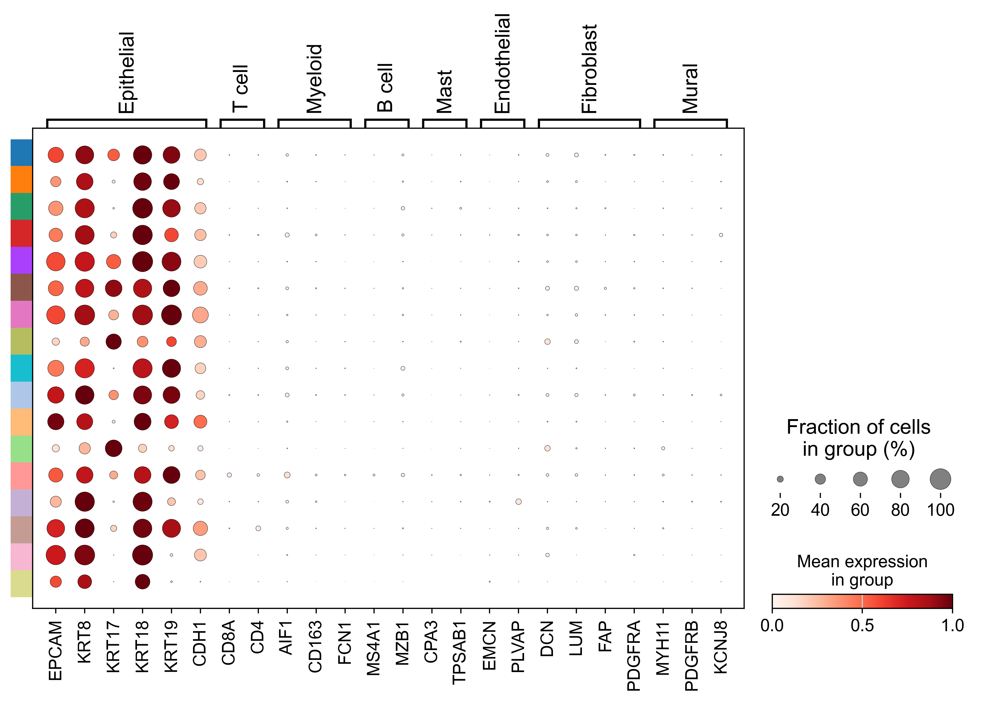

In [7]:
import matplotlib.colors as mcolors

marker_dict = {
    "Epithelial": ['EPCAM', 'KRT8', 'KRT17', 'KRT18', 'KRT19', 'CDH1'],
    "T cell": ['CD8A', 'CD4'],
    "Myeloid": ['AIF1','CD163','FCN1'],
    "B cell": ['MS4A1', 'MZB1'],
    "Mast": ['CPA3', 'TPSAB1'],
    "Endothelial": ['EMCN', 'PLVAP'],
    "Fibroblast": ['DCN','LUM','FAP','PDGFRA',],
    "Mural": ['MYH11', 'PDGFRB','KCNJ8'],
}

dp = sc.pl.dotplot(
    adata_endo5,
    groupby='res_0.62',
    var_names=marker_dict,
    standard_scale="group",
    return_fig=True,
    show=False,
)

axes = dp.get_axes()
ax = axes["mainplot_ax"]
fig = ax.figure

# row color bar
cats = adata_endo5.obs['res_0.62'].cat.categories
color_map = dict(zip(cats, adata_endo5.uns["res_0.62_colors"]))
row_colors = [color_map[c] for c in cats]
rgb = np.array([mcolors.to_rgb(c) for c in row_colors]).reshape(len(cats), 1, 3)

ax.set_yticklabels([])
ax.tick_params(axis="y", length=0)

pos = ax.get_position()
bar_ax = fig.add_axes([pos.x0 - 0.02, pos.y0 + 0.015, 0.022, pos.height - 0.03])
bar_ax.imshow(rgb, aspect="auto", origin="upper")
bar_ax.set_xticks([])
bar_ax.set_yticks([])
for spine in bar_ax.spines.values():
    spine.set_visible(False)

# size legend dots spacing
size_ax = axes["size_legend_ax"]
pos2 = size_ax.get_position()
size_ax.set_position([pos2.x0, pos2.y0, pos2.width * 1.8, pos2.height])
size_ax.set_title("Fraction of cells\nin group (%)", x=0.4, y=0.6)

coll = size_ax.collections[0]
offsets = coll.get_offsets()

new_x = np.array([0, 0.5, 1, 1.5, 2])[: offsets.shape[0]]
offsets[:, 0] = new_x
coll.set_offsets(offsets)

ticklabels = [t.get_text() for t in size_ax.get_xticklabels()]
size_ax.set_xticks(new_x)
size_ax.set_xticklabels(ticklabels)
size_ax.set_xlim(new_x.min() - 0.1, new_x.max() + 0.6)

color_ax = axes["color_legend_ax"]
pos3 = color_ax.get_position()
color_ax.set_position([pos3.x0, pos3.y0, pos3.width * 1.5, pos3.height])

# save as PDF (700 dpi)
fig.savefig("dotplot_res_0.62.pdf", dpi=700, bbox_inches="tight")

plt.show()

In [8]:
cluster_to_state = {
    '0':  'Epi_Cycle',
    '1':  'Epi_Luminal',
    '2':  'Epi_Hormonal',
    '3':  'Epi_Xenobiotic',
    '4':  'Epi_TNF',
    '5':  'Epi_Interferon',
    '6':  'Epi_Glandular',
    '7':  'Epi_Squamous',
    '8':  'Epi_Hypox-Stress',
    '9':  'Epi_cEMT',
    '10': 'Epi_ER-Stress',
    '11': 'Epi_Basal',
    '12': 'Epi_MHCII',
    '13': 'Epi_Hypox-Adapt',
    '14': 'Epi_Ciliated',
    '15': 'Epi_Oxphos-Ion',
    '16': 'Epi_Oxphos-Metal',
}

adata_endo5.obs['sub_anno'] = pd.Categorical(
    adata_endo5.obs['res_0.62'].astype(str).map(cluster_to_state),
    categories=list(cluster_to_state.values()),
    ordered=True,
)

In [9]:
sc.tl.rank_genes_groups(adata_endo5,groupby='sub_anno',method='wilcoxon')

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:45:13)





In [10]:
epi_state_genes = {
    'Cycle':['TOP2A','MKI67','STMN1','HMGB2'],#Epi0
    'Luminal':['AZGP1', 'TFF3', 'GATA3','FOXA1','ESR1'],#Epi1
    'Hormone-Response':['NKX3-1', 'TMPRSS2', 'STEAP2', 'MSMB','AR',
    'GREB1', 'SLC39A6', 'MLPH', 'SOCS2', 'FASN', 'CREB3L4', 'NR4A1'],#Epi2
    'Xenobiotic':['EPHX1',"MGST1", "AKR1C2","AKR1B10","SULT1A1",],#Epi3
    'TNF-Infla':['TNFRSF12A','CXCL1','MMP7','SAA1','SOD2'],#Epi4
    'Interferon':['ISG15','IFI44L','IFIT3','STAT1'],#Epi5
    'Glandular':['AGR2', 'MUC1', 'MUC13', 'TFF1','ELF3','LCN2'],#Epi6
    'Squamous':['DSG3','SERPINB5','SFN','CSTA','DSP'],#Epi7
    'Hypoxia-Stress':['NUPR1','SEC61G','SERP1','P4HB','TRIB3',#stress 
                        'HILPDA','EGLN3','BNIP3','BNIP3L'#hypoxia                     
                         ],#Epi8
    'cEMT':['MDK','MYL9','VIM','CCDC80','BGN','COL1A1','MARCKSL1','LGALS1'],#Epi9
    'ER-Stress':['CLU','HSP90B1','HSPA5','CALR',],#Epi10
    'Basal':['ITGB1','CAV1','KRT17','CALD1'],#Epi11
    'MHCII':['HLA-DRA','HLA-DRB1','HLA-DPA1','HLA-DPB1','HLA-DMB'],#Epi12
    'Hypoxic-Adaptive':['NDUFA4L2','PDK4','PLIN2','ANGPTL4'],#Epi13
    'Ciliated':['FOXJ1','CETN2','TPPP3','PIFO','RSPH1'],#Epi14
    'Oxphos-Ion':['CHCHD10','COX5A','COX7C',"NDUFA4",'NDUFA5','COX7A2', 'COX6C','OXCT1',#oxphos
                 'ATP6V0D2', 'RHCG','HSD11B2','SCIN','PVALB'#Ion
                 ],#Epi15
    'Oxphos-Metal':['SUCLG1', 'LDHB',  #oxphos
                   'GSTA1', 'GPX3', 'MT1G','MT1H','SOD1'#Metal
                    ],#Epi16
}

sc.pl.rank_genes_groups_dotplot(
    adata_endo5,
    groupby="sub_anno",
    values_to_plot="logfoldchanges",
    vmax=1.5,
    vmin=-1.5,
    cmap="coolwarm",
    var_names=epi_state_genes,
    dendrogram=False,
)

In [11]:
del adata_endo5.obs['res_0.62']

In [ ]:
adata_endo5.write_h5ad('/path/to/h5ad_annotated/_sc_Epithelial.h5ad')

In [12]:
adata=sc.read_h5ad('/path/to/h5ad_annotated/_sc_Epithelial.h5ad')

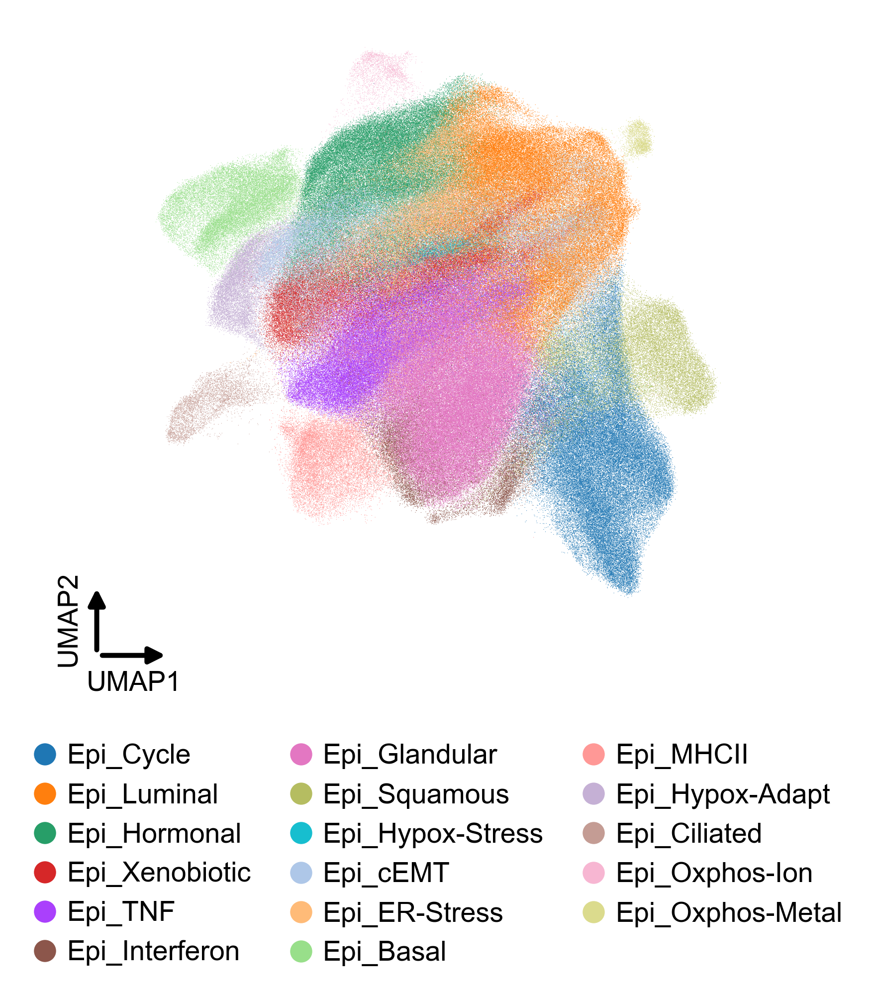

In [13]:
from plotting import umap_with_arrow_axes

umap_with_arrow_axes(adata)

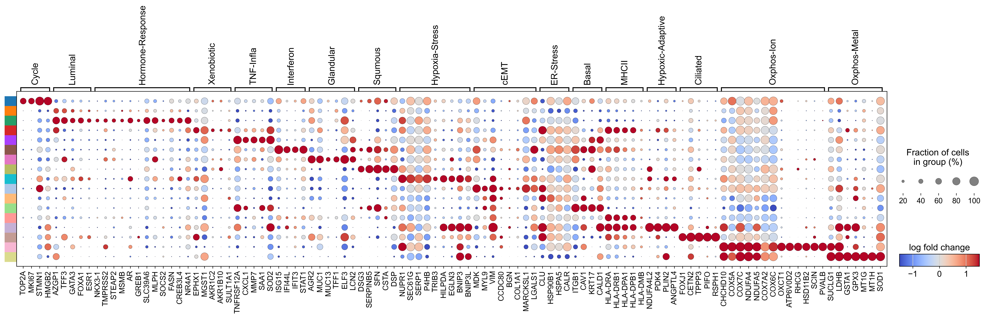

In [14]:
import matplotlib.colors as mcolors

state_order = [
    'Epi_Cycle',
    'Epi_Luminal',
    'Epi_Hormonal',
    'Epi_Xenobiotic',
    'Epi_TNF',
    'Epi_Interferon',
    'Epi_Glandular',
    'Epi_Squamous',
    'Epi_Hypox-Stress',
    'Epi_cEMT',
    'Epi_ER-Stress',
    'Epi_Basal',
    'Epi_MHCII',
    'Epi_Hypox-Adapt',
    'Epi_Ciliated',
    'Epi_Oxphos-Ion',
    'Epi_Oxphos-Metal',
]

mp = sc.pl.rank_genes_groups_dotplot(
    adata,
    groupby="sub_anno",
    values_to_plot="logfoldchanges",
    vmax=1.5,
    vmin=-1.5,
    figsize=(26, 5),
    cmap="coolwarm",
    var_names=epi_state_genes,
    dendrogram=False,
    return_fig=True,
    show=False,
)

axes = mp.get_axes()
ax = axes["mainplot_ax"]
fig = ax.figure

# row color bar
cats = state_order
all_cats = adata.obs["sub_anno"].cat.categories
color_map = dict(zip(all_cats, adata.uns["sub_anno_colors"]))
row_colors = [color_map[c] for c in cats]
rgb = np.array([mcolors.to_rgb(c) for c in row_colors]).reshape(len(cats), 1, 3)

ax.set_yticklabels([])
ax.tick_params(axis="y", length=0)

pos = ax.get_position()
bar_ax = fig.add_axes([pos.x0 - 0.01, pos.y0 + 0.019, 0.016, pos.height - 0.04])
bar_ax.imshow(rgb, aspect="auto", origin="upper")
bar_ax.set_xticks([])
bar_ax.set_yticks([])
for spine in bar_ax.spines.values():
    spine.set_visible(False)

# size legend dots spacing
size_ax = axes["size_legend_ax"]
pos2 = size_ax.get_position()
size_ax.set_position([pos2.x0, pos2.y0, pos2.width * 1.8, pos2.height])
size_ax.set_title("Fraction of cells\nin group (%)", x=0.4, y=0.6)

coll = size_ax.collections[0]
offsets = coll.get_offsets()

new_x = np.array([0, 0.5, 1, 1.5, 2])[: offsets.shape[0]]
offsets[:, 0] = new_x
coll.set_offsets(offsets)

ticklabels = [t.get_text() for t in size_ax.get_xticklabels()]
size_ax.set_xticks(new_x)
size_ax.set_xticklabels(ticklabels)
size_ax.set_xlim(new_x.min() - 0.1, new_x.max() + 0.6)

color_ax = axes["color_legend_ax"]
color_ax.set_title("log fold change", fontsize=14)
color_ax.tick_params(labelsize=13)
pos3 = color_ax.get_position()
color_ax.set_position([pos3.x0, pos3.y0, pos3.width * 1.5, pos3.height])
fig.savefig("dotplot_sub_state.pdf", dpi=700, bbox_inches="tight")
plt.show()